In [34]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

#Limites maximos de las coordenadas de los rectangulos
MAX_X = 100
MAX_ALTURA = 50
MIN_ANCHO = 5
MAX_ANCHO = 25

In [35]:
def crear_rectangulos():
    rectangulos = []

    cantidad = int(input("¿Cuántos rectángulos deseas generar? "))

    for _ in range(cantidad):
        # Generar coordenadas aleatorias
        izquierda = random.randint(0, MAX_X - MIN_ANCHO)
        ancho = random.randint(MIN_ANCHO, MAX_ANCHO)

        # Evitar que la coordenada derecha exceda MAX_X
        derecha = min(izquierda + ancho, MAX_X)

        altura = random.randint(1, MAX_ALTURA)

        # Guardar la tripleta (izquierda, altura, derecha)
        rectangulos.append((izquierda, altura, derecha))

    return rectangulos

In [36]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def dibujar_rectangulos(rectangulos):
    if not rectangulos:
        print("No hay rectángulos para dibujar.")
        return

    fig, ax = plt.subplots(figsize=(12, 6))

    for izquierda, altura, derecha in rectangulos:
        ancho = derecha - izquierda

        rectangulo = Rectangle(
            (izquierda, 0),
            ancho,
            altura,
            facecolor="skyblue",
            edgecolor="blue",
            alpha=0.45,
            linewidth=1.5
        )

        ax.add_patch(rectangulo)

    # Calcular los límites a partir de los rectángulos
    min_x = min(r[0] for r in rectangulos)
    max_x = max(r[2] for r in rectangulos)
    max_altura = max(r[1] for r in rectangulos)

    # Añadir un margen del 5 % en X y del 15 % en Y
    margen_x = (max_x - min_x) * 0.05
    margen_y = max_altura * 0.15

    # Evitar márgenes nulos
    margen_x = max(margen_x, 0.5)
    margen_y = max(margen_y, 0.5)

    ax.set_xlim(min_x - margen_x, max_x + margen_x)
    ax.set_ylim(0, max_altura + margen_y)

    # Configurar el plano cartesiano
    ax.set_xlabel("Coordenada X")
    ax.set_ylabel("Altura (Y)")
    ax.set_title("Rectángulos generados aleatoriamente")

    ax.axhline(y=0, color="black", linewidth=1)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    plt.show()

In [37]:
def dibujar_contorno(franjas):
    if not franjas:
        print("No hay franjas para dibujar.")
        return

    # Ordenar las franjas por coordenada izquierda
    franjas = sorted(franjas, key=lambda f: f[0])

    # Calcular los límites de las coordenadas
    min_x = min(f[0] for f in franjas)
    max_x = max(f[0] for f in franjas)
    max_altura = max(f[1] for f in franjas)

    # Agregar márgenes para los bordes
    margen_x = max((max_x - min_x) * 0.05, 0.5)
    margen_y = max_altura * 0.15
    margen_y = max(margen_y, 0.5)

    # La última franja se extiende hasta el límite derecho con margen
    limite_derecho = max_x + margen_x

    # Crear un espacio de dibujo independiente
    fig, ax = plt.subplots(figsize=(12, 6))

    for i in range(len(franjas)):
        izquierda, altura = franjas[i]

        # Determinar el final de la franja
        if i < len(franjas) - 1:
            derecha = franjas[i + 1][0]
        else:
            derecha = limite_derecho

        ancho = derecha - izquierda

        # Dibujar la franja si tiene ancho y altura positivos
        if ancho > 0 and altura > 0:
            franja = Rectangle(
                (izquierda, 0),
                ancho,
                altura,
                facecolor="salmon",
                edgecolor="red",
                alpha=0.5,
                linewidth=1.5
            )
            ax.add_patch(franja)

    # Ajustar automáticamente los límites del plano
    ax.set_xlim(min_x - margen_x, limite_derecho)
    ax.set_ylim(0, max_altura + margen_y)

    # Configurar etiquetas y presentación
    ax.set_xlabel("Coordenada X")
    ax.set_ylabel("Altura (Y)")
    ax.set_title("Contorno formado por franjas")

    ax.axhline(y=0, color="black", linewidth=1)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set


Tripletas almacenadas:
[(1, 11, 5), (2, 6, 7), (3, 13, 9), (12, 7, 16), (14, 3, 25), (19, 18, 22)]


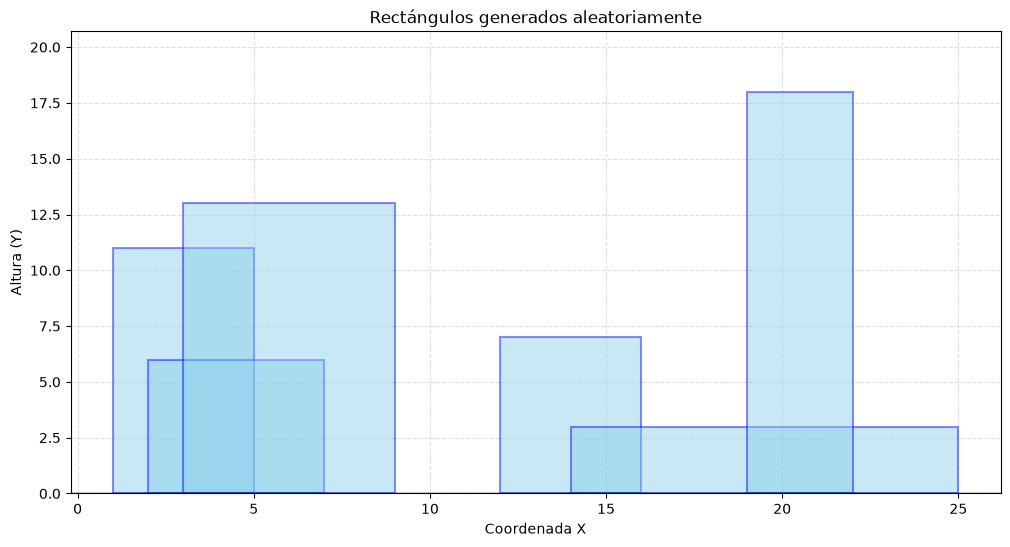

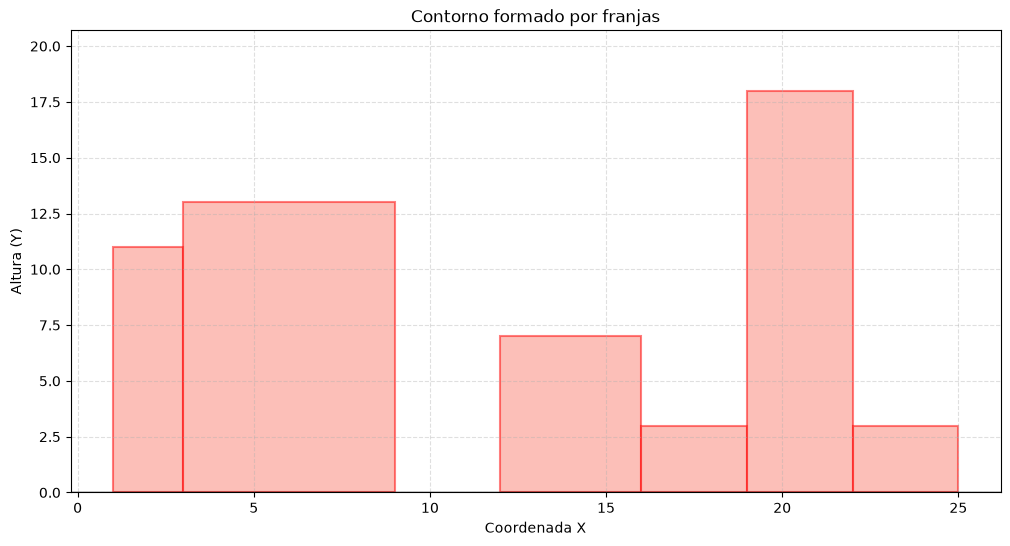

In [38]:
# Crear y almacenar las tripletas
# rectangulos = crear_rectangulos()
rectangulos = [(1,11,5), (2,6,7), (3,13,9), (12,7,16), (14,3,25), (19,18,22)]
franjas = [(1,11), (3,13), (9,0), (12,7), (16,3), (19,18), (22,3), (25,0)]

# Mostrar las tripletas ingresadas
print("\nTripletas almacenadas:")
print(rectangulos)

# Dibujar los rectángulos
dibujar_rectangulos(rectangulos)
dibujar_contorno(franjas)